# Notebook 06: Scenario 3 - Combined Dataset Analysis
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization
**Data analysed:** the cleaned real data and the synthetic data appended into one table (24,398 sessions) with a new column `Data_Source` ("Real" or "Synthetic").

The question of this scenario is what happens when the two datasets are analysed together: do the groups differ, do relationships stay the same, does combining create new extremes, and does it improve representation or introduce bias? The same bins, axis limits and settings as in notebooks 04 and 05 are used (shared through `src/scenario_lib.py`); in the group plots each source is expressed as a share of its own rows, so the two halves are comparable.

## 1. Setup and the combined dataset

In [1]:
import sys, json, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import scenario_lib as L
L.use_style()

real = pd.read_csv(ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv")
syn = pd.read_csv(ROOT / "data" / "synthetic" / "synthetic_online_shoppers.csv")
S = L.make_settings(real, syn)
FIG = ROOT / "figures" / "combined" / "scenario3"
RES = ROOT / "results" / "scenarios" / "scenario3_combined"
(ROOT / "data" / "combined").mkdir(parents=True, exist_ok=True); RES.mkdir(parents=True, exist_ok=True)

comb = L.combine(real, syn)                      # real rows first, then synthetic rows; Data_Source is the last column
comb.to_csv(ROOT / "data" / "combined" / "combined_dataset.csv", index=False)

# checks on the combined file
back = pd.read_csv(ROOT / "data" / "combined" / "combined_dataset.csv")
assert len(back) == len(real) + len(syn) and list(back.columns) == list(real.columns) + ["Data_Source"]
assert back.Data_Source.value_counts().to_dict() == {"Real": len(real), "Synthetic": len(syn)}
assert back.isna().sum().sum() == 0
print("Combined:", back.shape, "|", back.Data_Source.value_counts().to_dict(), "| missing values:", int(back.isna().sum().sum()))
print("SHA-256 of data/combined/combined_dataset.csv:", hashlib.sha256((ROOT / "data" / "combined" / "combined_dataset.csv").read_bytes()).hexdigest())

Combined: (24398, 25) | {'Real': 12199, 'Synthetic': 12199} | missing values: 0
SHA-256 of data/combined/combined_dataset.csv: 4e0c63ffa6f12cb7fcafff69735e819256bde59d67a94b0593292f9345a7bca7


## 2. Overall statistics of the combined data

In [2]:
overall = L.univariate_numeric(comb, S); overall.to_csv(RES / "overall_numeric.csv")
overall[["mean", "median", "std", "Q1", "Q3", "skewness", "IQR outliers (%)", "zeros (%)"]].round(3)

,mean,median,std,Q1,Q3,skewness,IQR outliers (%),zeros (%)
column,,,,,,,,
Administrative,2.248,1.000,2.990,0.000,4.000,1.913,2.279,44.721
Administrative_Duration,70.386,13.000,135.132,0.000,88.742,4.106,8.222,47.549
Informational,0.576,0.000,1.151,0.000,1.000,3.101,6.361,73.088
Informational_Duration,27.516,0.000,91.559,0.000,0.000,6.590,22.707,77.293
ProductRelated,32.253,17.000,43.445,7.000,38.000,3.105,8.517,0.131
ProductRelated_Duration,1221.899,574.695,1825.687,200.209,1420.804,3.129,9.025,3.918
BounceRates,0.017,0.004,0.037,0.000,0.017,3.677,10.173,44.889
ExitRates,0.041,0.025,0.044,0.014,0.050,2.201,7.857,0.312
PageValues,5.849,0.000,15.039,0.000,5.347,6.443,15.940,72.383


In [3]:
cat_overall = L.categorical_freq(comb); cat_overall.to_csv(RES / "overall_categorical_frequency.csv", index=False)
cat_overall[cat_overall.column.isin(["Revenue", "VisitorType", "Weekend", "Quarter"])].round(2).reset_index(drop=True)

,column,level,count,percent
0,Quarter,Q4,10464,42.89
1,Quarter,Q2,7303,29.93
2,Quarter,Q1,3990,16.35
3,Quarter,Q3,2641,10.82
4,VisitorType,Returning_Visitor,20936,85.81
5,VisitorType,New_Visitor,3306,13.55
6,VisitorType,Other,156,0.64
7,Weekend,Weekday,18813,77.11
8,Weekend,Weekend,5585,22.89
9,Revenue,No_Purchase,20759,85.08


**Interpretation.** The combined table has 24,398 sessions, half real and half synthetic. Its statistics lie between the two sources and are close to the real ones for the well-reproduced columns (ProductRelated mean 32.3, Total_Pages 35.1, Total_Duration 1,320 s, ExitRates 0.041). For the sparse columns the pooled values are a blend: PageValues has a mean of 5.85, a standard deviation of 15.0 (real 18.7, synthetic 10.2) and 72% zeros (real 78%, synthetic 67%). The overall purchase rate is 14.9%. Because the pooled values are an average of two different distributions, they describe neither source exactly.

## 3. Group comparison by `Data_Source`
### 3.1 Means, spread and distribution tests (Real against Synthetic)
Cohen's d is the difference in means divided by the pooled standard deviation; KS is the largest distance between the two distribution functions. With about 12,000 rows per group, p-values are tiny for almost any difference, so the effect sizes are the more informative numbers.

In [4]:
gc = L.group_comparison(comb); gc.to_csv(RES / "group_comparison.csv")
gc.assign(**{"KS p": gc["KS p"].map(lambda p: "<0.0001" if p < 1e-4 else f"{p:.4f}"),
             "Mann-Whitney p": gc["Mann-Whitney p"].map(lambda p: "<0.0001" if p < 1e-4 else f"{p:.4f}")}).round(3)

,mean Real,mean Synthetic,mean Combined,mean diff (%),std Real,std Synthetic,std Combined,Cohen d,KS,KS p,Mann-Whitney p
column,,,,,,,,,,,
Administrative,2.340,2.156,2.248,-7.864,3.331,2.601,2.990,-0.062,0.090,<0.0001,0.0009
Administrative_Duration,79.493,61.279,70.386,-22.913,157.518,107.446,135.132,-0.135,0.046,<0.0001,0.0428
Informational,0.509,0.643,0.576,26.413,1.276,1.007,1.151,0.117,0.127,<0.0001,<0.0001
Informational_Duration,32.767,22.264,27.516,-32.053,120.155,47.692,91.559,-0.115,0.094,<0.0001,<0.0001
ProductRelated,31.572,32.934,32.253,4.313,40.690,46.027,43.445,0.031,0.031,<0.0001,0.1119
ProductRelated_Duration,1183.082,1260.716,1221.899,6.562,1652.525,1983.100,1825.687,0.043,0.045,<0.0001,0.2594
BounceRates,0.020,0.014,0.017,-31.778,0.045,0.025,0.037,-0.177,0.047,<0.0001,0.1179
ExitRates,0.041,0.040,0.041,-3.467,0.046,0.041,0.044,-0.033,0.031,<0.0001,0.6307
PageValues,5.953,5.746,5.849,-3.464,18.658,10.209,15.039,-0.014,0.136,<0.0001,<0.0001


**Interpretation.** The difference between the sources is small for most columns when measured by effect size: Cohen's d is below 0.18 in absolute value for every column, and the mean differs by less than 8% for nine of the 14 columns. The largest relative differences are in BounceRates (-31.8%), Informational_Duration (-32.1%), Administrative_Duration (-22.9%), Informational (+26.4%) and Avg_Time_Per_Page (+15.4%). Distribution distances are larger than the mean differences suggest: KS is 0.136 for PageValues, 0.127 for Informational, 0.094 for Informational_Duration, 0.090 for Administrative and 0.087 for Product_Page_Share, so the two sources differ in the shape of the distribution more than in the mean. Mann-Whitney tests are significant (p < 0.0001) for Informational, Informational_Duration, PageValues, Avg_Time_Per_Page and Product_Page_Share, not significant for ProductRelated, its duration, ExitRates, BounceRates, SpecialDay, Total_Pages and Total_Duration, and borderline for Administrative (p = 0.001) and Administrative_Duration (p = 0.043).

### 3.2 Combined histogram

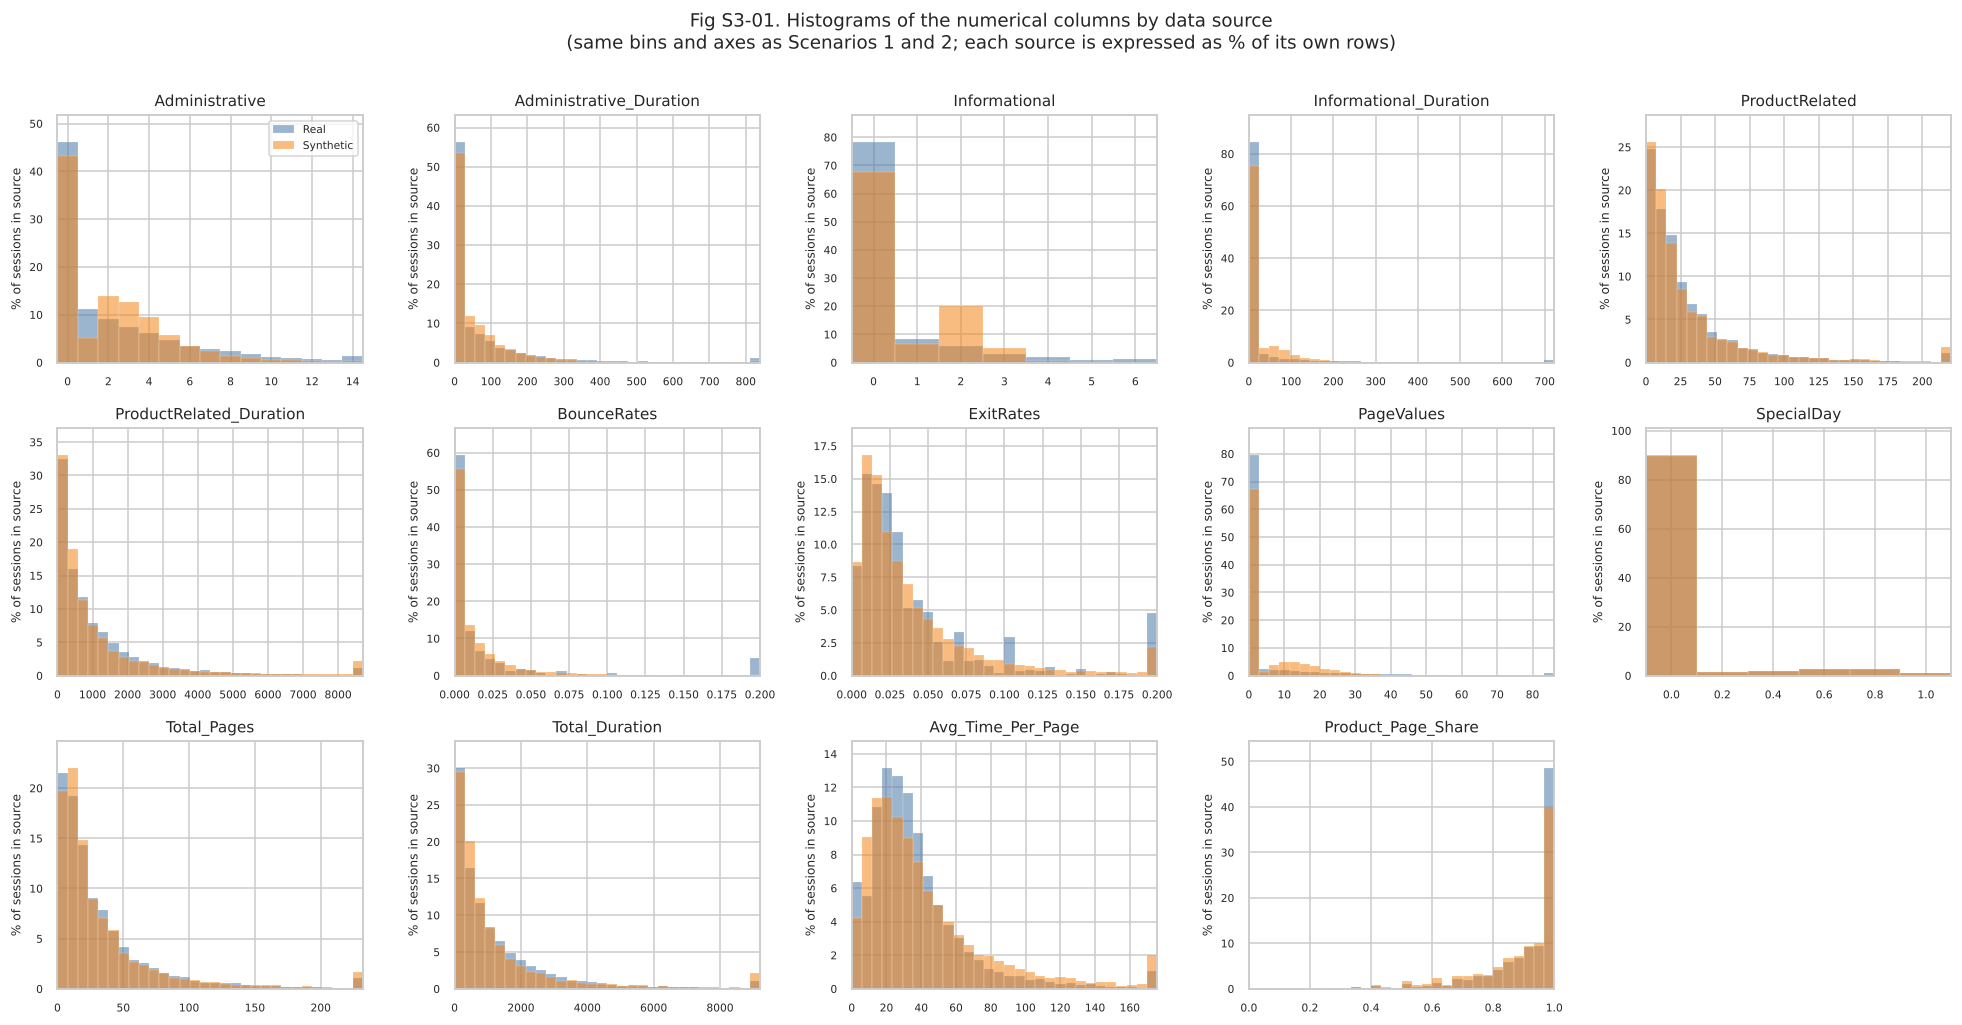

In [5]:
L.fig_combined_hist(comb, S, "Fig S3-01. Histograms of the numerical columns by data source", FIG / "s3_01_combined_histograms.png")

**Interpretation.** With each source drawn as a share of its own rows on the same bins, the two histograms overlap almost completely for ProductRelated, its duration, Total_Pages, Total_Duration, SpecialDay and ExitRates. They separate for Administrative (synthetic bumps at 2 to 4 pages), Informational (the synthetic excess at 2 and the missing tail), PageValues (fewer synthetic zeros and a synthetic bump at 10 to 20) and BounceRates and ExitRates (a smaller synthetic spike at the cap of 0.2). The combined histogram would therefore look like a smoothed version of the real one in these columns.

### 3.3 Grouped box plots

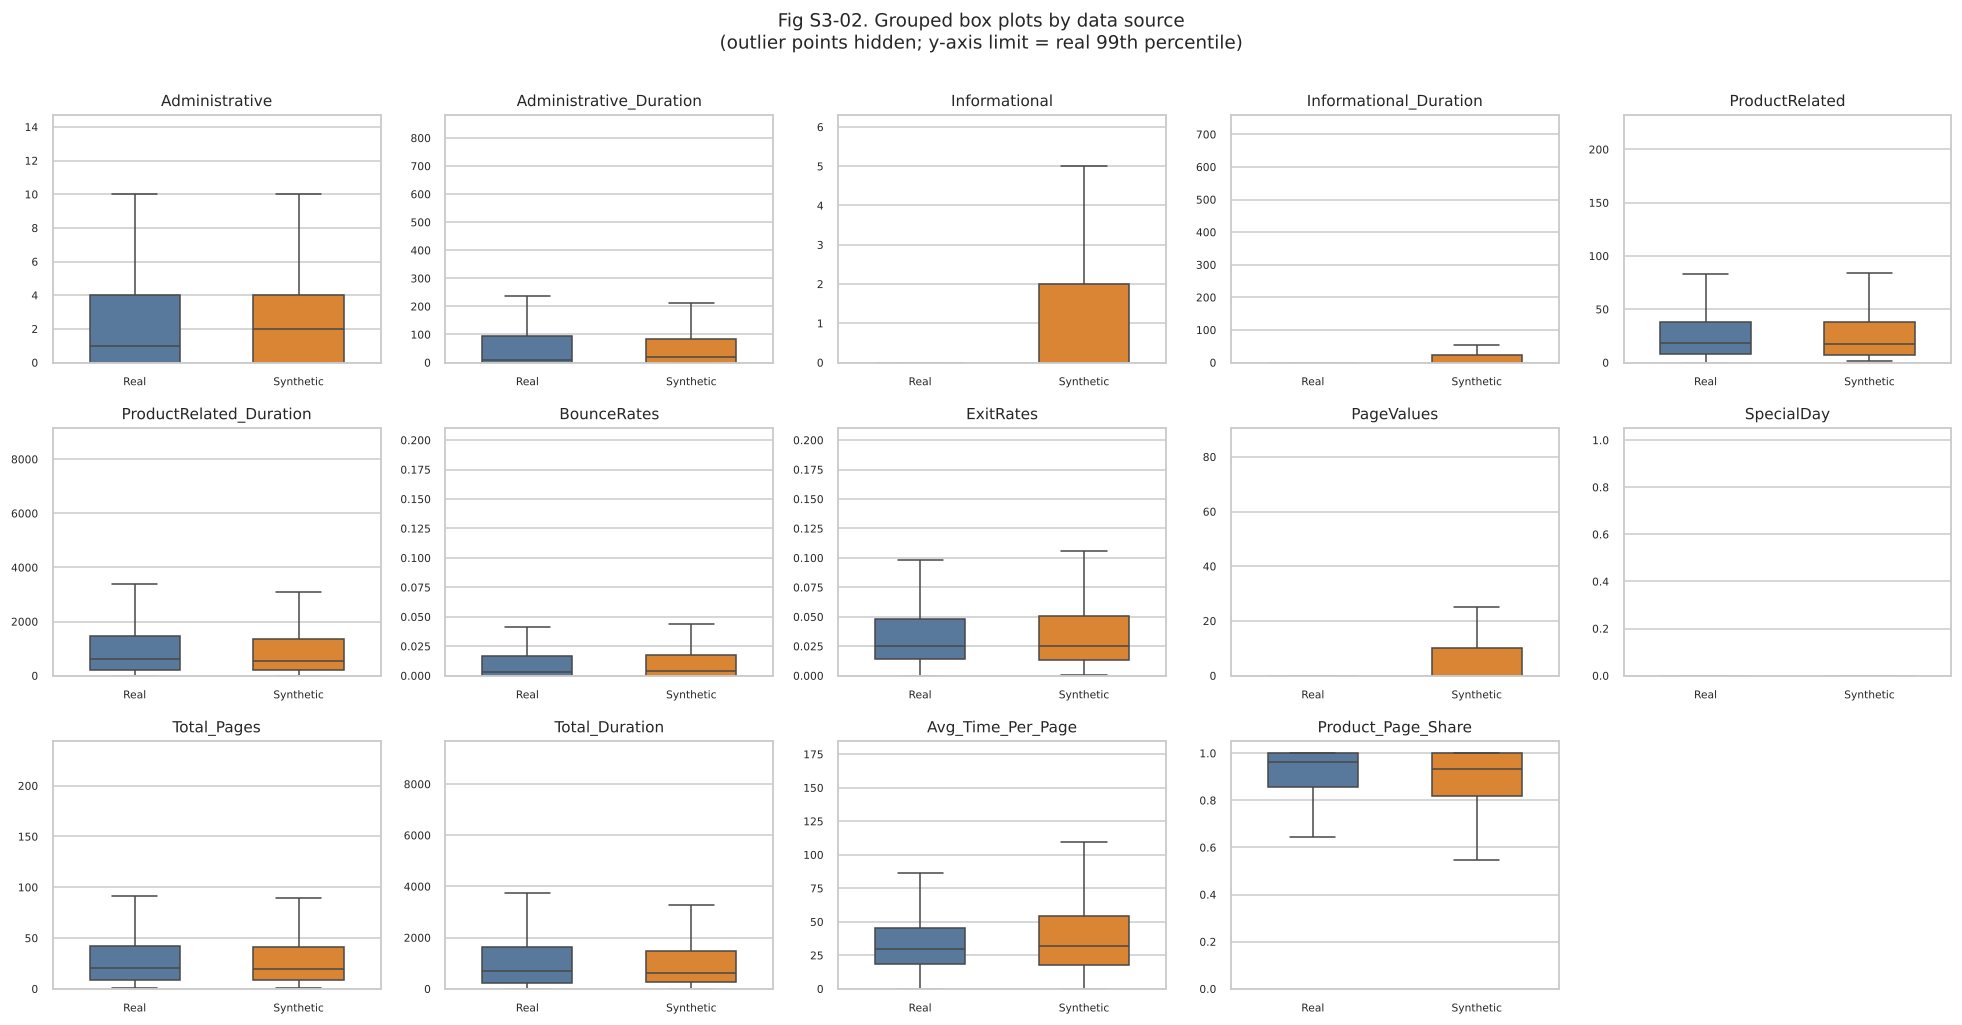

In [6]:
L.fig_grouped_box(comb, S, "Fig S3-02. Grouped box plots by data source", FIG / "s3_02_grouped_boxplots.png")

**Interpretation.** The grouped box plots agree for the count and duration columns. The visible differences are the collapsed real boxes of Informational and PageValues (more than 75% zeros) against synthetic boxes that extend to 2 and about 10, a lower synthetic whisker for the durations of Administrative and ProductRelated, and a somewhat taller synthetic box for Avg_Time_Per_Page. They show that the synthetic data has a larger share of mid-sized non-zero values in the sparse columns.

### 3.4 Violin plots

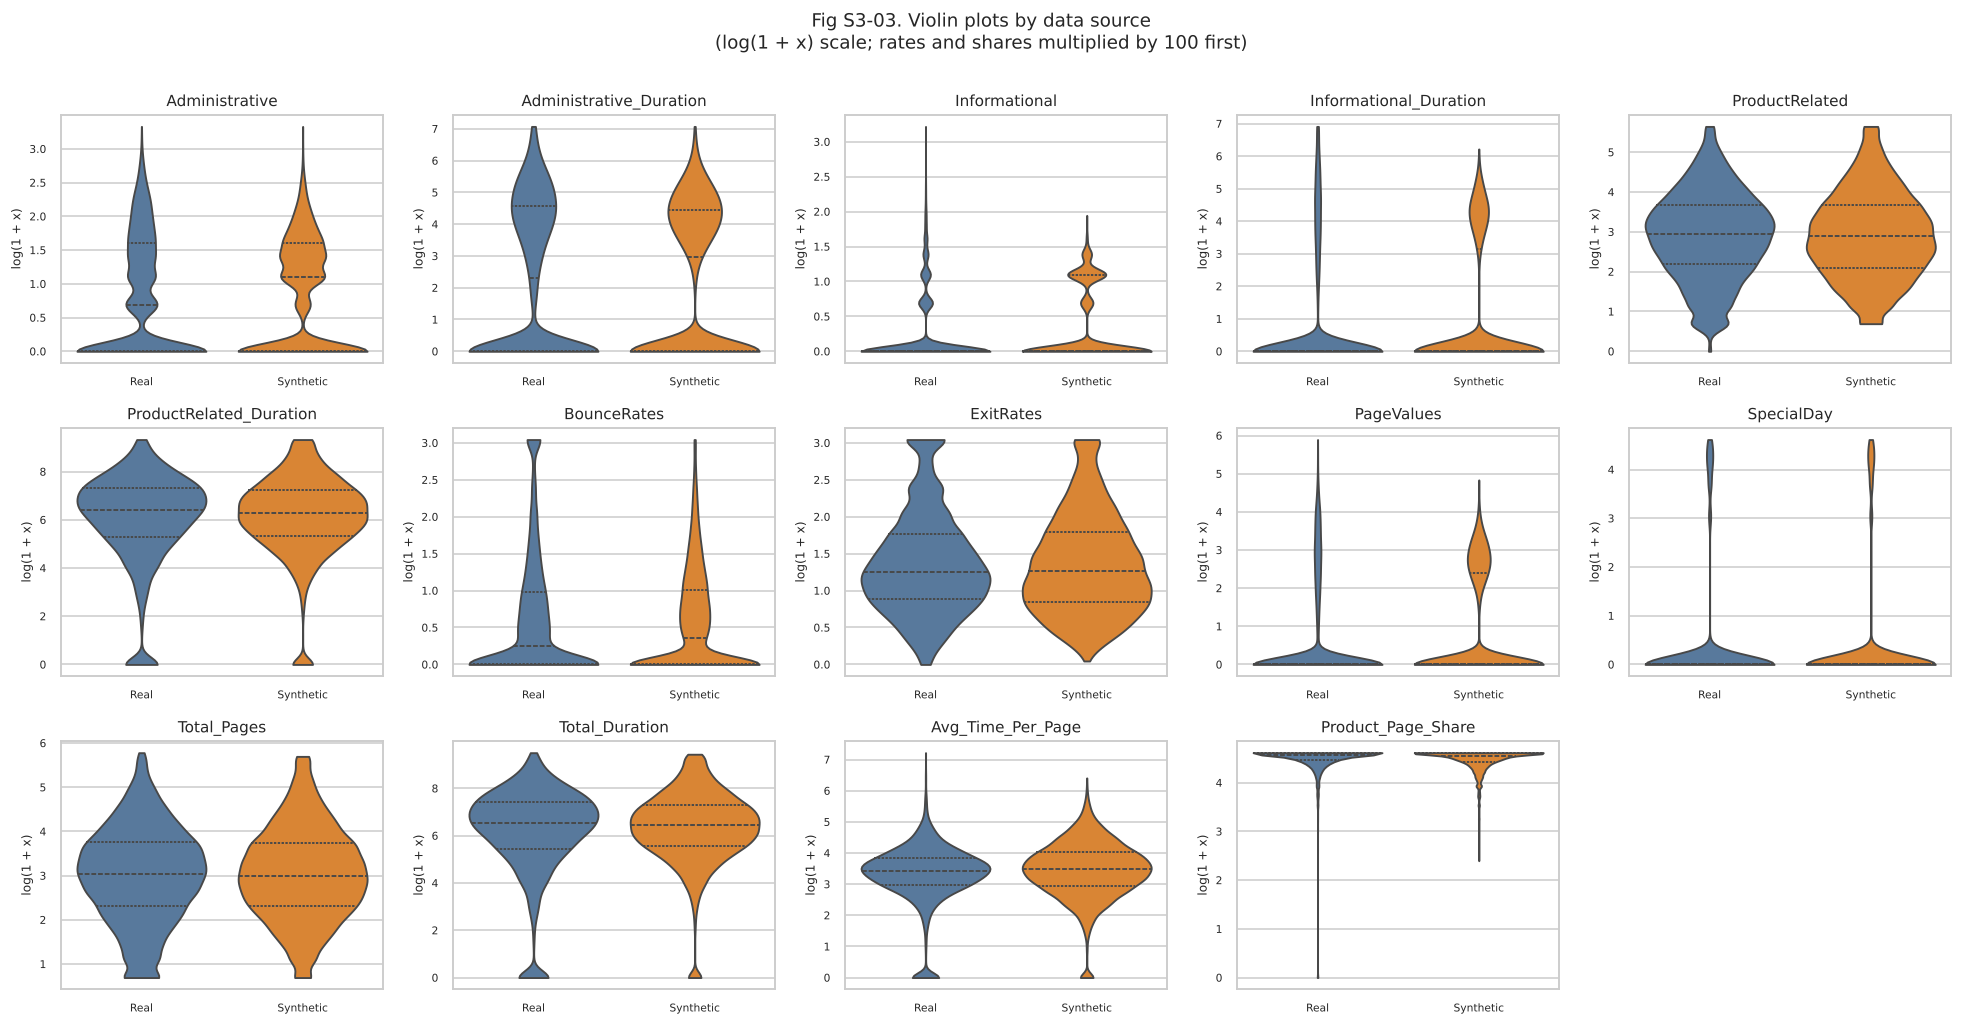

In [7]:
L.fig_violins(comb, S, "Fig S3-03. Violin plots by data source", FIG / "s3_03_violins.png")

**Interpretation.** On the log scale the shapes of the violins are similar for the duration, count and share columns. The differences are in the sparse columns: the real PageValues and Informational_Duration violins have a long thin tail towards high values that the synthetic violins lack, while the synthetic PageValues and Informational violins have a pronounced bulge in the middle (PageValues around log 2.5, Informational at 2 pages). The zero mass at the base is similar in the duration columns and smaller in the synthetic PageValues and Informational columns.

### 3.5 Category proportions by source (grouped bar charts)

Largest differences in category share (percentage points):


,column,level,Real %,Synthetic %,diff (pp),chi2 p,Cramer's V
72,Revenue,No_Purchase,84.36,85.81,1.45,0.00,0.02
73,Revenue,Purchase,15.64,14.19,-1.45,0.00,0.02
20,OperatingSystems,OS_2,53.60,55.03,1.43,0.35,0.02
69,Session_Length_Band,Long,32.81,31.67,-1.14,0.16,0.01
17,Weekend,Weekday,76.57,77.65,1.07,0.05,0.01
18,Weekend,Weekend,23.43,22.35,-1.07,0.05,0.01
60,TrafficType,Traffic_2,32.05,32.95,0.89,0.81,0.02
10,Quarter,Q1,16.73,15.98,-0.75,0.38,0.01


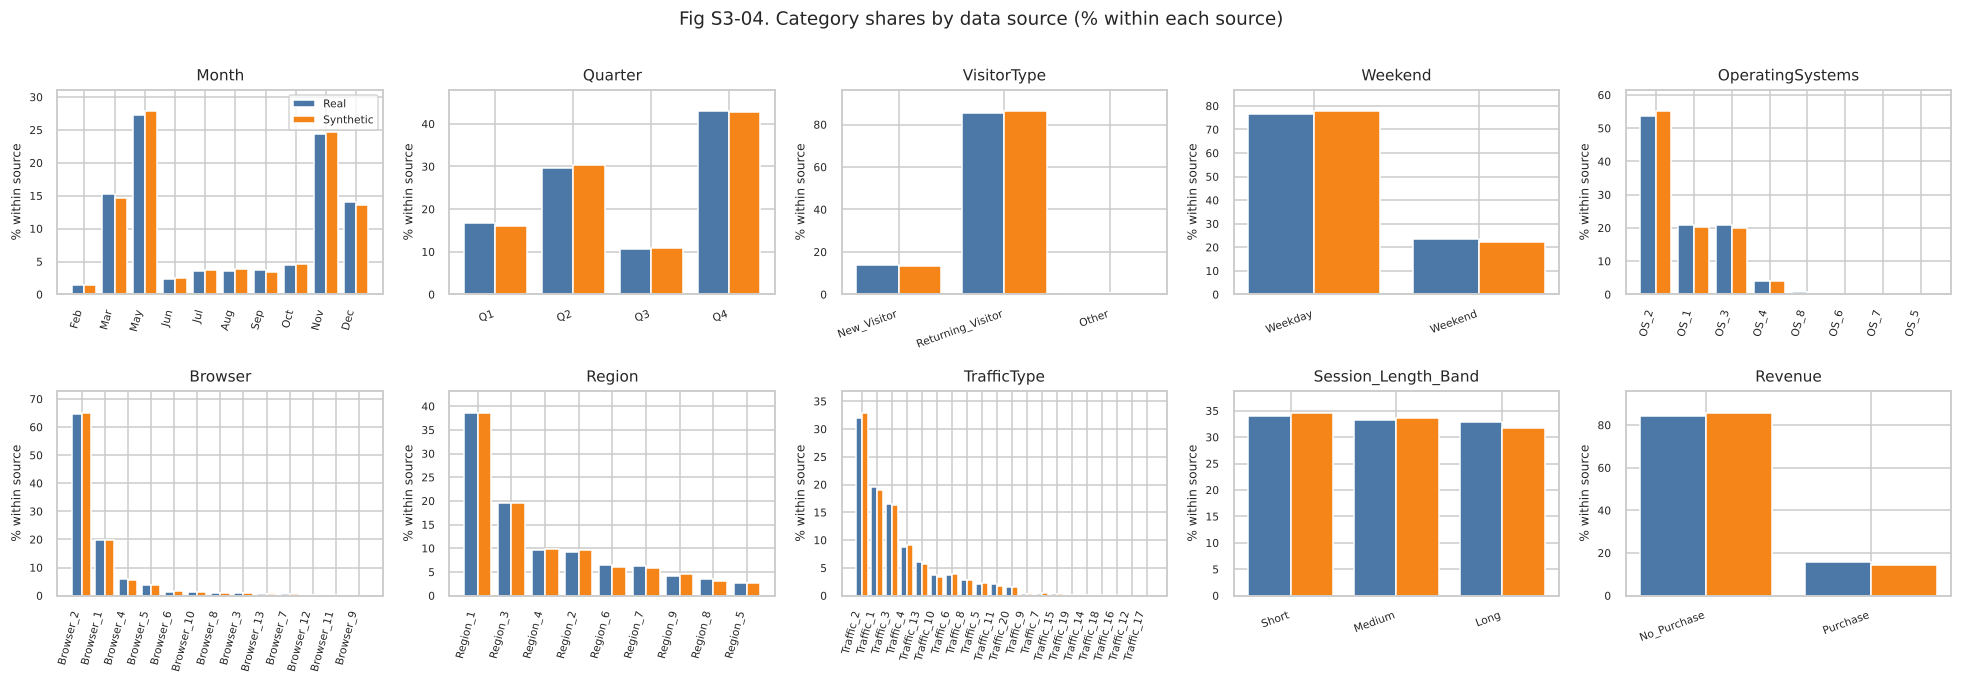

In [8]:
cp = L.category_proportions(comb); cp.to_csv(RES / "category_proportions.csv", index=False)
print("Largest differences in category share (percentage points):")
display(cp.reindex(cp["diff (pp)"].abs().sort_values(ascending=False).index).head(8).round(2))
L.fig_grouped_cat_bars(comb, S, "Fig S3-04. Category shares by data source (% within each source)", FIG / "s3_04_grouped_category_bars.png")

**Interpretation.** The grouped bars of the two sources are almost identical for every categorical column. The largest difference in any category share is 1.45 percentage points (Revenue: 15.6% purchases in the real data and 14.2% in the synthetic data), followed by OS_2 (+1.4), the long session band (-1.1) and weekday (+1.1). Cramér's V between source and category is between 0.010 and 0.024 for all ten columns. In terms of one-way category proportions, the combined data is equivalent to the real data.

### 3.6 Overall statistical comparison chart

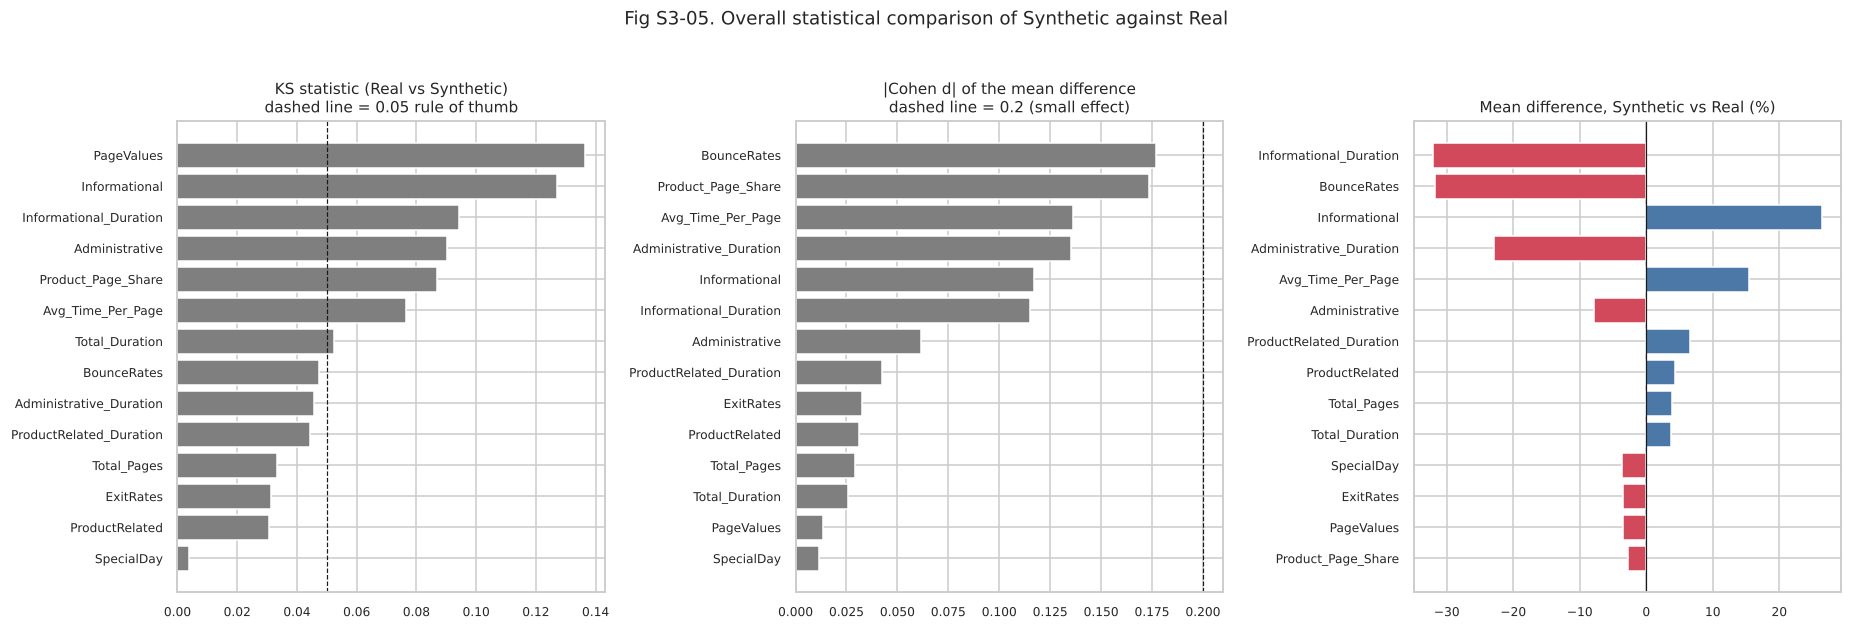

In [9]:
L.fig_overall_comparison(gc, "Fig S3-05. Overall statistical comparison of Synthetic against Real", FIG / "s3_05_overall_comparison.png")

**Interpretation.** The three panels summarise the group comparison. By KS, seven of the 14 columns exceed the 0.05 rule of thumb (the smallest of them is Total_Duration at 0.052). By Cohen's d no column reaches the 0.2 small-effect line (the largest are BounceRates -0.18 and Product_Page_Share -0.17), so the mean differences are small. The percentage panel shows that the largest relative differences are for sparse columns with small means (BounceRates, Informational, Informational_Duration, Administrative_Duration). The synthetic data is therefore close to the real data in its centre and further from it in shape.

## 4. Relationship comparison: does the correlation between key variables stay the same?

In [10]:
rc = L.relationship_comparison(comb); rc.to_csv(RES / "relationship_comparison.csv")
rc.round(3)

,Spearman Real,Spearman Synthetic,Spearman Combined,Pearson Real,Pearson Synthetic,Pearson Combined
pair,,,,,,
ProductRelated ~ ProductRelated_Duration,0.879,0.743,0.812,0.875,0.666,0.754
BounceRates ~ ExitRates,0.589,0.447,0.520,0.902,0.519,0.753
ExitRates ~ PageValues,-0.304,-0.206,-0.251,-0.174,-0.149,-0.161
Total_Pages ~ PageValues,0.348,0.259,0.297,0.067,0.142,0.090
Administrative ~ Administrative_Duration,0.939,0.867,0.904,0.649,0.699,0.665
Total_Duration ~ PageValues,0.364,0.261,0.306,0.067,0.147,0.092
BounceRates ~ Avg_Time_Per_Page,-0.154,0.129,-0.014,-0.174,0.105,-0.076


**Interpretation.** Every combined correlation lies between the real and synthetic value, so combining averages the relationships instead of reproducing them. Examples (Spearman): ProductRelated with its duration 0.88 real, 0.74 synthetic, 0.81 combined; ExitRates with PageValues -0.30, -0.21 and -0.25. The strongest linear relation, BounceRates with ExitRates, falls from a Pearson of 0.90 to 0.52 in the synthetic data and 0.75 in the combined data. The pair BounceRates and Avg_Time_Per_Page has opposite signs in the two sources (-0.15 real, +0.13 synthetic), and in the combined data the two cancel to -0.01, which wrongly suggests that there is no relationship. For this pair the combined data hides a difference instead of showing it.

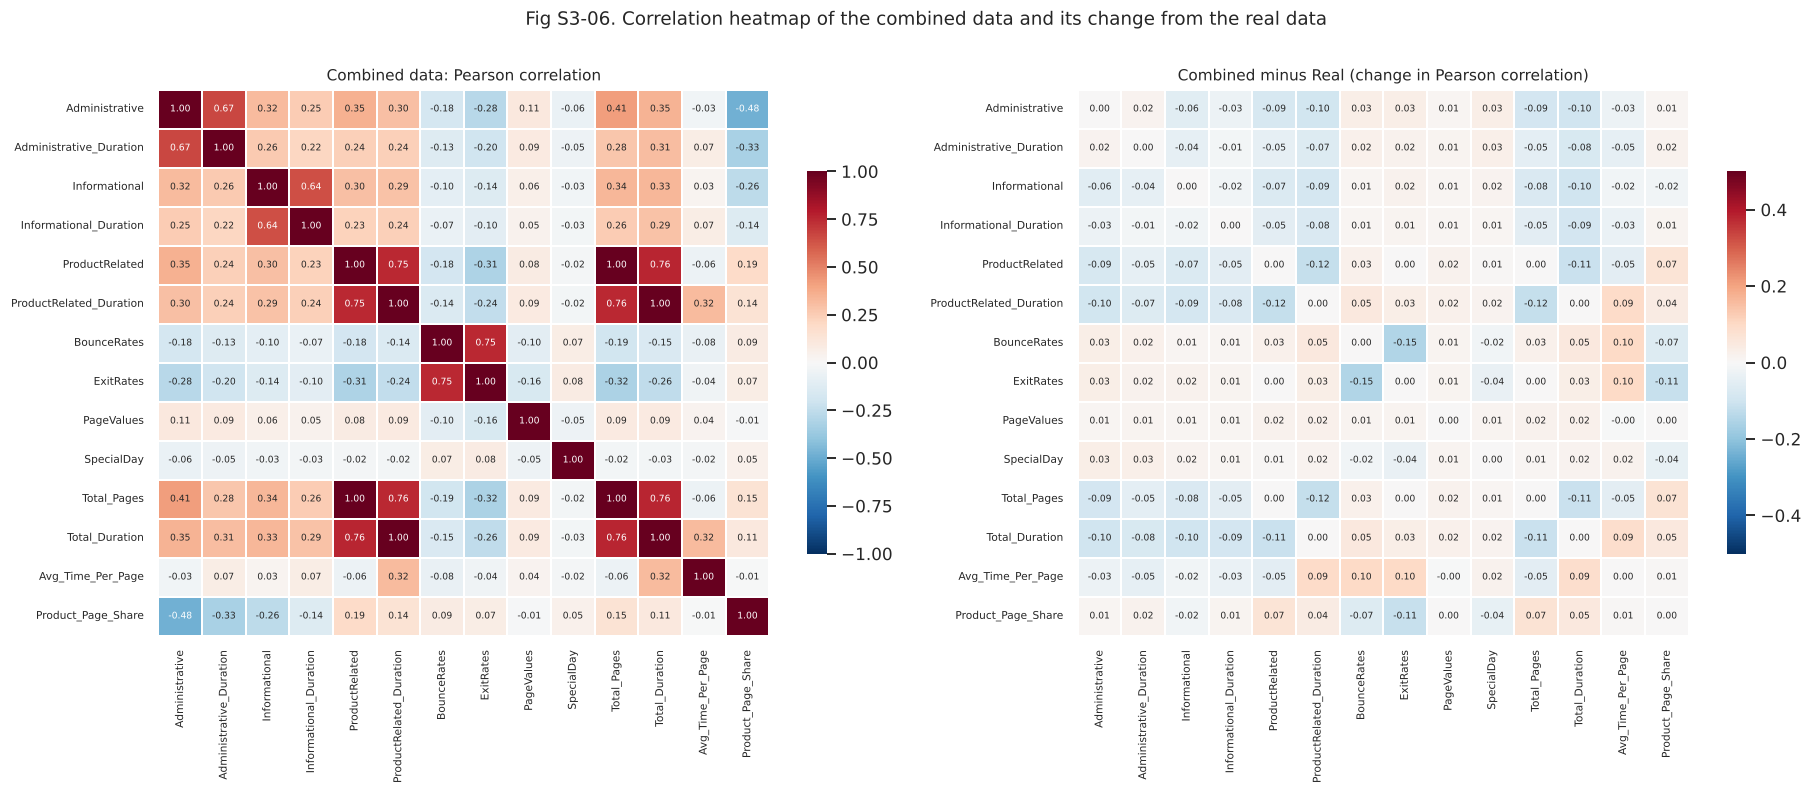

In [11]:
L.fig_combined_heatmap(comb, "Fig S3-06. Correlation heatmap of the combined data and its change from the real data", FIG / "s3_06_combined_heatmap.png")

**Interpretation.** The combined heatmap has the same structure as the real one. The right panel shows how far each correlation moves when the synthetic rows are added: the average absolute change is 0.04 and the largest is 0.15 (BounceRates with ExitRates, -0.15), followed by ProductRelated with its duration (-0.12), ProductRelated_Duration with Total_Pages (-0.12) and ExitRates with Product_Page_Share (-0.11). All of the larger changes are reductions of strong real correlations. The shifts are moderate because half of the data is real, but they are systematically in the direction of weaker relationships.

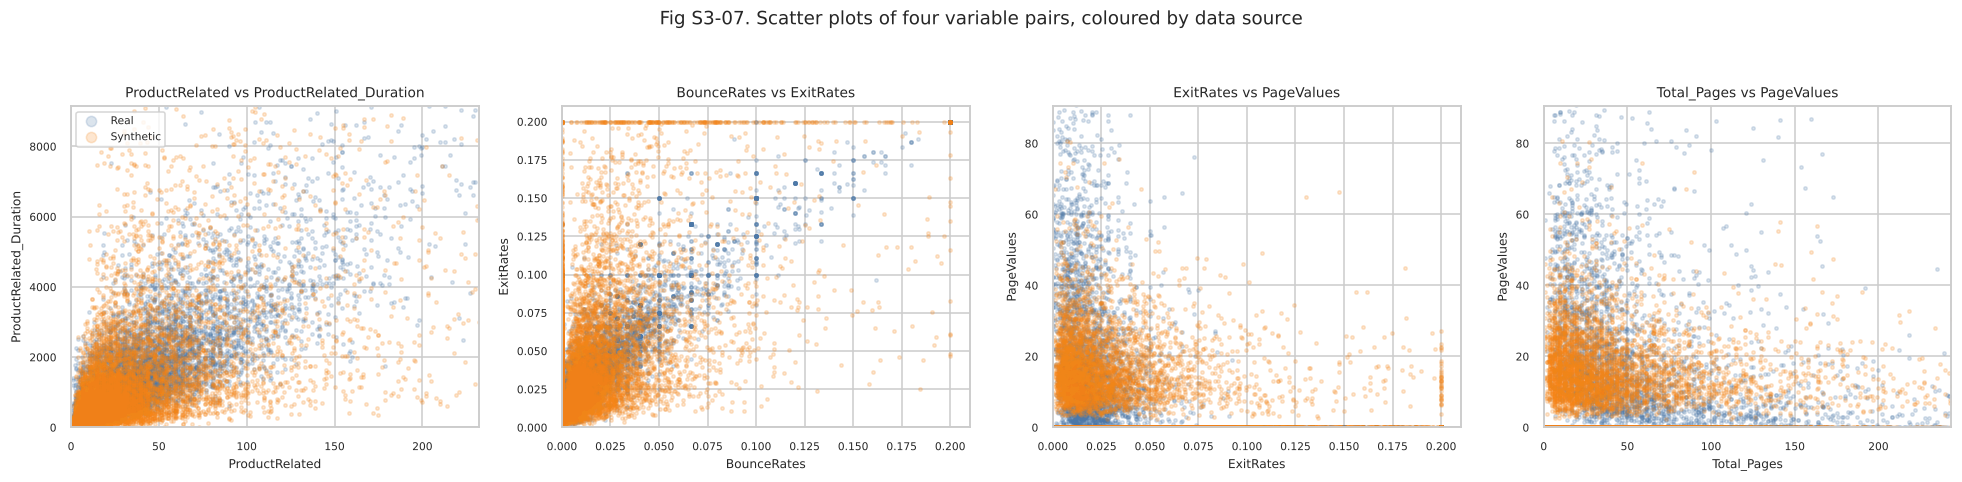

In [12]:
L.fig_scatter_by_source(comb, S, "Fig S3-07. Scatter plots of four variable pairs, coloured by data source", FIG / "s3_07_scatter_by_source.png")

**Interpretation.** In all four panels the real (blue) and synthetic (orange) points overlap over most of the plane, so a viewer of the combined plot cannot tell the sources apart in the dense region. Differences are at the edges: the cap at an exit or bounce rate of 0.2 has fewer synthetic points (2.0% against 4.8% of sessions for ExitRates and 0.2% against 4.7% for BounceRates), and the synthetic points fill the middle of the PageValues range more evenly than the real points.

## 5. Outlier analysis: does combining create new extremes or change the variance?
Fences are the usual 1.5 x IQR. 'Combined fences' are computed on the combined data; the last column of the first table applies the *real* fences to the synthetic rows. A 'new extreme' would be a combined maximum above the real maximum.

In [13]:
oc = L.outlier_comparison(comb); oc.to_csv(RES / "outlier_comparison.csv")
show = oc[["outliers Real (own fences) %", "outliers Synthetic (own fences) %", "outliers Combined (combined fences) %",
           "synthetic rows beyond Real fences %"]]
display(show.round(2))
display(oc[["max Real", "max Synthetic", "max Combined", "std Real", "std Synthetic", "std Combined", "std Combined / std Real",
            "Levene p (Real vs Synth)"]].round(3))
new_ext = (oc["max Combined"] > oc["max Real"]).sum()
print("Columns where the combined maximum is above the real maximum (new extremes):", int(new_ext))
print("Columns where the synthetic maximum is below the real maximum:", int((oc["max Synthetic"] < oc["max Real"]).sum()), "of", len(oc))
print("Std of the combined data relative to real: min %.2f, median %.2f, max %.2f" % (oc["std Combined / std Real"].min(),
      oc["std Combined / std Real"].median(), oc["std Combined / std Real"].max()))

,outliers Real (own fences) %,outliers Synthetic (own fences) %,outliers Combined (combined fences) %,synthetic rows beyond Real fences %
column,,,,
Administrative,3.31,1.25,2.28,1.25
Administrative_Duration,9.40,6.63,8.22,5.39
Informational,21.57,0.01,6.36,32.26
Informational_Duration,19.71,17.26,22.71,25.70
ProductRelated,8.25,8.94,8.52,9.18
ProductRelated_Duration,7.80,10.10,9.03,9.02
BounceRates,11.66,8.25,10.17,8.80
ExitRates,10.81,7.54,7.86,8.38
PageValues,22.38,5.83,15.94,32.86


,max Real,max Synthetic,max Combined,std Real,std Synthetic,std Combined,std Combined / std Real,Levene p (Real vs Synth)
column,,,,,,,,
Administrative,27.000,27.000,27.000,3.331,2.601,2.990,0.898,0.000
Administrative_Duration,1178.967,1178.967,1178.967,157.518,107.446,135.132,0.858,0.000
Informational,24.000,6.000,24.000,1.276,1.007,1.151,0.902,0.000
Informational_Duration,1005.421,501.570,1005.421,120.155,47.692,91.559,0.762,0.000
ProductRelated,282.000,282.000,282.000,40.690,46.027,43.445,1.068,0.001
ProductRelated_Duration,11246.177,11246.177,11246.177,1652.525,1983.100,1825.687,1.105,0.000
BounceRates,0.200,0.200,0.200,0.045,0.025,0.037,0.811,0.000
ExitRates,0.200,0.200,0.200,0.046,0.041,0.044,0.952,0.033
PageValues,361.764,125.004,361.764,18.658,10.209,15.039,0.806,0.284


Columns where the combined maximum is above the real maximum (new extremes): 0
Columns where the synthetic maximum is below the real maximum: 6 of 14
Std of the combined data relative to real: min 0.76, median 0.97, max 1.10


**Interpretation.** Combining does not create new extremes. In all 14 columns the combined maximum equals the real maximum, because the synthetic maximum is never higher; for six columns (Informational, Informational_Duration, PageValues, Total_Pages, Total_Duration and Avg_Time_Per_Page) the synthetic maximum is lower than the real one, so the synthetic rows only contribute values inside the real range. The variance changes in both directions: the combined standard deviation is 76% to 90% of the real one for the sparse columns (Informational_Duration 0.76, PageValues 0.81, BounceRates 0.81, Administrative_Duration 0.86), and 5% to 10% larger for the browsing columns (ProductRelated_Duration 1.10, Total_Duration 1.08, Total_Pages 1.05), where the synthetic data has a longer upper tail. The Levene test (centred at the median) finds a significant difference of spread (5% level) for eleven columns but not for PageValues, SpecialDay or Total_Duration, although its standard deviation differs by 45% between the sources: the test compares the typical spread around the median and is insensitive to the tail weight.

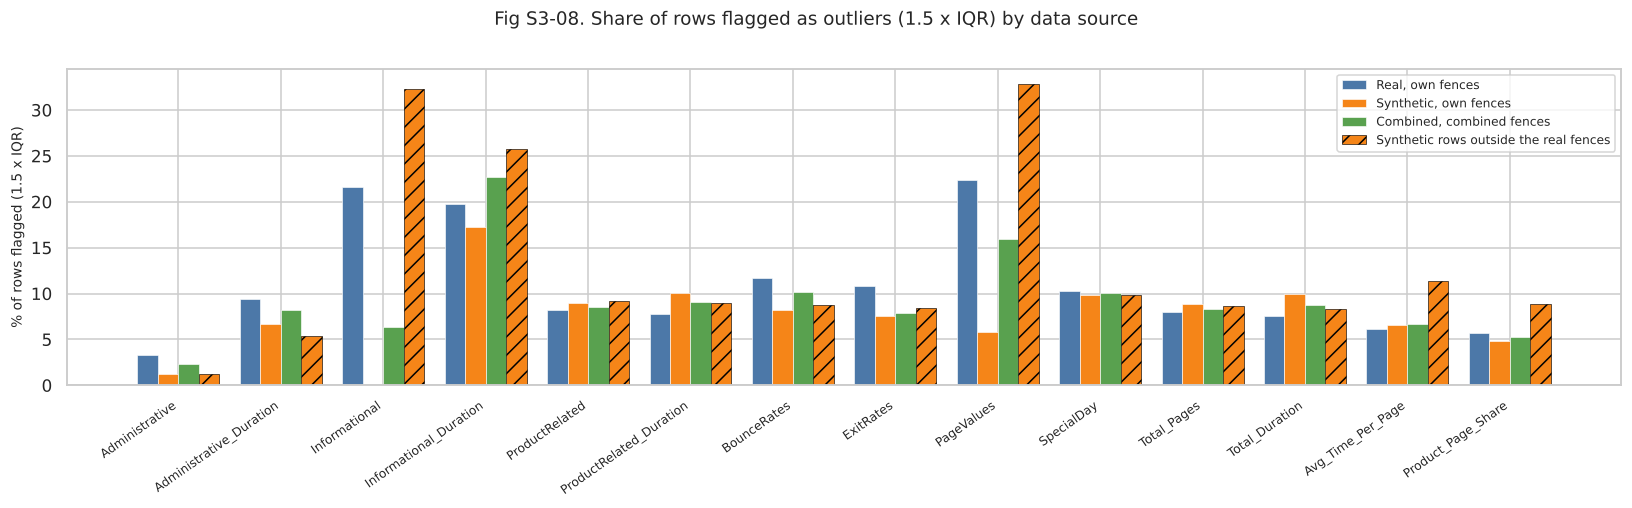

In [14]:
L.fig_outlier_rates(oc, "Fig S3-08. Share of rows flagged as outliers (1.5 x IQR) by data source", FIG / "s3_08_outlier_rates.png")

**Interpretation.** The share of rows flagged as outliers is usually between the real and the synthetic share when the combined fences are used (for example PageValues 22.4%, 5.8% and 15.9%; Informational 21.6%, 0.01% and 6.4%), because the combined quartiles are a mixture. This means the outlier count of the combined data is not a reliable number for either source. The hatched bars apply the real fences to the synthetic rows: 32.3% of synthetic Informational values and 32.9% of synthetic PageValues are outside the real fences, because the real fences collapse at 0 (Q3 = 0) and every non-zero synthetic value is flagged. For Avg_Time_Per_Page (11.4%) and Product_Page_Share (8.9%) the synthetic data has more rows beyond the real fences than the real data itself (6.1% and 5.7%).

## 6. One multivariate plot

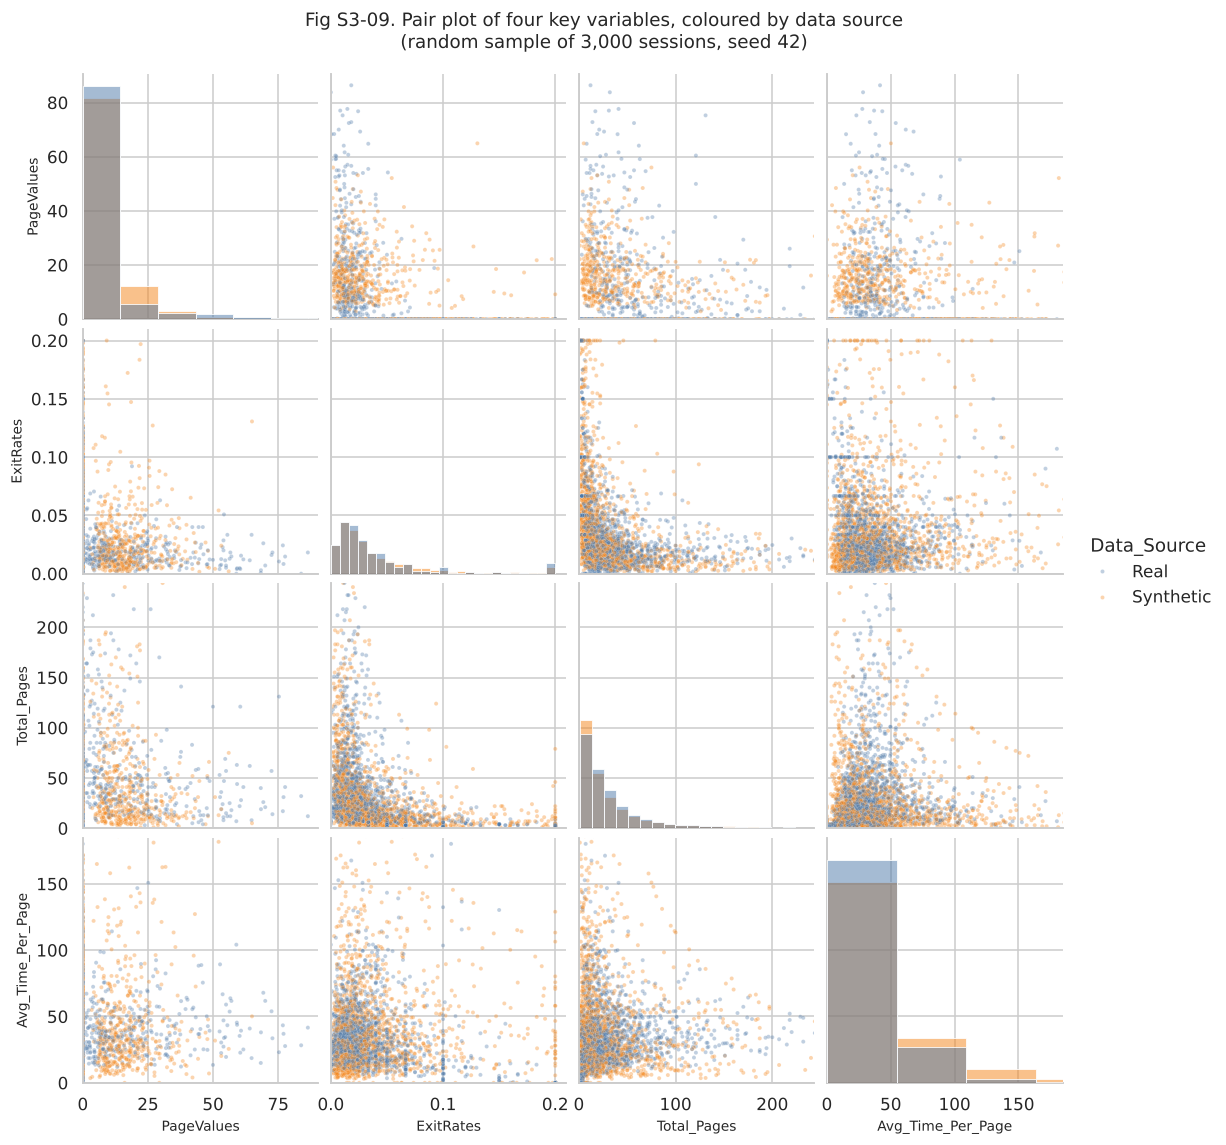

In [15]:
L.fig_pairplot(comb, S, "Fig S3-09. Pair plot of four key variables, coloured by data source", FIG / "s3_09_pairplot_by_source.png", hue="Data_Source", palette=L.SCENARIO_COLOR, n=3000)

**Interpretation.** The pair plot uses a random sample of 3,000 rows of the combined data (seed 42) and shows blue and orange points mixed in every panel. As in the scatter plots, the overlap is nearly complete in the centre and the differences are in the tails and in the cap at 0.2. The diagonal histograms agree in overall shape; the real data has a taller first bin for PageValues and for Avg_Time_Per_Page.

## 7. Does combining improve representation or introduce bias?
The same measures of the purchase signal are computed on the real data, the synthetic data and the combined data. If the synthetic half added real information, the combined values would move towards the truth; if it only copies and weakens it, they move towards the synthetic values.

In [16]:
bt = L.bias_table(comb); bt.to_csv(RES / "bias_table.csv")
bt.round(3)

,Real,Synthetic,Combined
sessions,12199.000,12199.000,24398.000
purchase rate (%),15.641,14.190,14.915
"purchase rate, 95% lower",15.007,13.582,14.474
"purchase rate, 95% upper",16.296,14.820,15.368
rank-biserial: PageValues by Revenue,0.726,0.302,0.526
rank-biserial: ExitRates by Revenue,-0.399,-0.175,-0.289
rank-biserial: Total_Pages by Revenue,0.318,0.141,0.234
rank-biserial: Total_Duration by Revenue,0.344,0.151,0.256
Cramer's V: VisitorType x Revenue,0.103,0.036,0.070
Cramer's V: Quarter x Revenue,0.137,0.039,0.087


**Interpretation.** For every measure of the purchase signal, the combined value lies between the real and the synthetic value, close to the midpoint. The purchase rate is 14.9% (real 15.6%, synthetic 14.2%). The rank-biserial effect of PageValues is 0.53 (0.73 real, 0.30 synthetic), 28% lower than in the real data. Cramér's V of purchase with month is 0.096 (0.176 and 0.053), 45% lower than in the real data; with quarter 0.087 (0.137 and 0.039), 37% lower; with visitor type 0.070 (0.103 and 0.036), 32% lower. The measure of the weekend effect falls from 0.027 to 0.012. So the combined data does not move the estimate towards the truth: it moves it half way to the synthetic value.

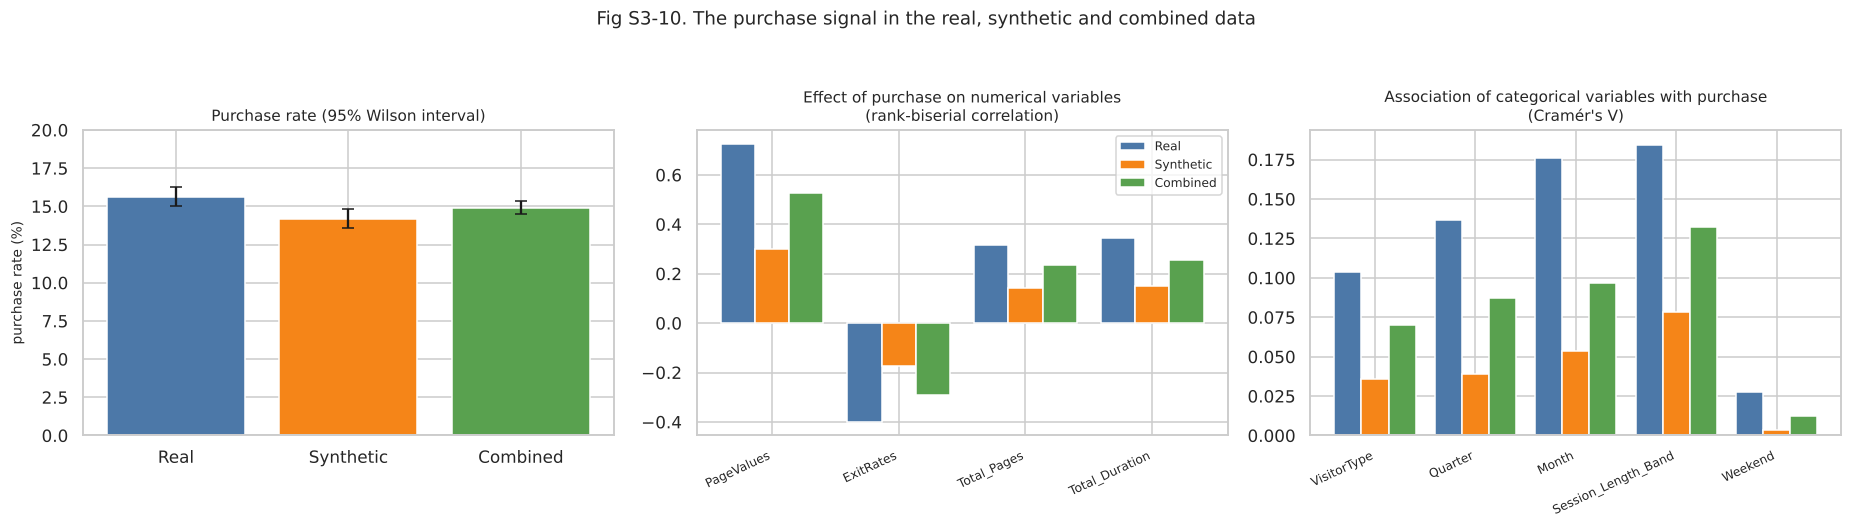

In [17]:
L.fig_bias(bt, "Fig S3-10. The purchase signal in the real, synthetic and combined data", FIG / "s3_10_bias_check.png")

**Interpretation.** The left panel shows the purchase rate with its 95% interval. The real rate of 15.6% lies above the interval of the combined data (about 14.5% to 15.4%), which means that an analyst working on the combined data would conclude that the real rate is too high, although it is the true value in the data. The two right panels show the same pattern for effect sizes: the green (combined) bars are about half way between the blue and the orange ones for each variable, so every association with purchase is understated compared with the real data.

In [18]:
# what the doubled sample size does to the precision (the synthetic rows are not independent of the real rows)
n_r, n_c = len(real), len(comb)
k_r, k_c = (real.Revenue == "Purchase").sum(), (comb.Revenue == "Purchase").sum()
w_r = np.diff(L.wilson(k_r, n_r))[0] * 100; w_c = np.diff(L.wilson(k_c, n_c))[0] * 100
print(f"Width of the 95% interval of the purchase rate: real {w_r:.2f} pp, combined {w_c:.2f} pp  (ratio {w_c / w_r:.2f}; sqrt(1/2) = 0.71)")
print(f"Combined purchase rate {100 * k_c / n_c:.2f}% against real {100 * k_r / n_r:.2f}%; the real rate lies "
      f"{'inside' if L.wilson(k_c, n_c)[0] * 100 <= 100 * k_r / n_r <= L.wilson(k_c, n_c)[1] * 100 else 'outside'} the interval of the combined rate")

Width of the 95% interval of the purchase rate: real 1.29 pp, combined 0.89 pp  (ratio 0.69; sqrt(1/2) = 0.71)
Combined purchase rate 14.92% against real 15.64%; the real rate lies outside the interval of the combined rate


**Interpretation.** The interval of the combined purchase rate is about 0.69 times as wide as that of the real data (0.89 against 1.29 percentage points), which is what doubling the sample size would give (the square root of one half is 0.71). But the synthetic half of the data is a function of the real half (it was fitted to it), so it carries no new information about the real population; the narrower interval is a false sense of precision. In the combined data the real purchase rate lies outside the 95% interval, which shows that the combined sample estimates a different quantity than the real data does.

## 8. Key findings

### Summary of the key findings


**Finding 1: The sources are close on the mean and far apart on shape.**
*Observation:* group means differ by less than 8% for nine of 14 columns and no column reaches Cohen's d of 0.2, but distributions differ in shape. *Statistical evidence:* KS above 0.05 for seven columns (PageValues 0.136, Informational 0.127, Informational_Duration 0.094, Administrative 0.090, Product_Page_Share 0.087); Mann-Whitney p < 0.0001 for five columns. *Figures:* S3-01 to S3-03, S3-05. *Significance:* a comparison of means alone would call the synthetic data good; tests on the full distribution show where it differs.

**Finding 2: Category proportions are the same in both sources.**
*Observation:* the share of every category differs by at most 1.45 percentage points between the sources. *Statistical evidence:* Cramér's V between source and category is 0.010 to 0.024 for all ten categorical columns; the largest gap is Revenue (15.6% against 14.2% purchases). *Figure:* S3-04. *Significance:* for one-way category counts, the combined data represents the real data well.

**Finding 3: Relationships are averaged, and a sign difference can be hidden.**
*Observation:* every correlation of the combined data lies between the real and synthetic value. *Statistical evidence:* BounceRates with ExitRates Pearson 0.90 (real), 0.52 (synthetic), 0.75 (combined); the average absolute shift of the 91 correlations from the real data is 0.04 and the largest is 0.15, all reductions of strong correlations. BounceRates with Avg_Time_Per_Page has Spearman -0.15 (real) and +0.13 (synthetic) and -0.01 combined. *Figures:* S3-06, S3-07. *Significance:* combining changes the strength of relationships and can hide the sign difference between the sources.

**Finding 4: Combining creates no new extremes, but it changes the variance and the outlier counts.**
*Observation:* the combined maximum equals the real maximum in all 14 columns, and in six columns the synthetic maximum is lower. *Statistical evidence:* the combined standard deviation is 76% to 90% of the real one for sparse columns and 105% to 110% for the product, page and duration columns; the share of outliers in PageValues is 22.4% (real), 5.8% (synthetic) and 15.9% (combined). *Figures:* S3-02, S3-08. *Significance:* outlier counts and standard deviations from the combined data describe neither source and should not be used for either.

**Finding 5: Combining introduces bias towards weaker effects and a lower purchase rate.**
*Observation:* all measures of the purchase signal in the combined data lie about half way between the real and synthetic values. *Statistical evidence:* purchase rate 14.9% (real 15.6%); rank-biserial of PageValues 0.53 against 0.73 (28% lower); Cramér's V of month with purchase 0.096 against 0.176 (45% lower), quarter 37% lower, visitor type 32% lower. *Figure:* S3-10. *Significance:* conclusions about purchase drivers drawn on the combined data are biased towards weaker effects than the real data shows.

**Finding 6: Combining does not improve representation; the extra precision is not real.**
*Observation:* the interval of the combined purchase rate is 0.69 times as wide as the real one, but the real rate lies outside it (15.6% against 14.5% to 15.4%). *Statistical evidence:* the synthetic rows were generated from the real rows, so they add no independent information; the combined sample behaves as if the sample size doubled while it did not. *Figures:* S3-10. *Significance:* for the columns that the generator reproduces well (ProductRelated, ExitRates, SpecialDay, Total_Pages; |d| < 0.04, KS < 0.05) the combination is harmless, but it never adds information about the population. It is useful for demonstrations, privacy-preserving sharing and testing, not for estimating real-world effects.

## 9. Outputs
Combined data: `data/combined/combined_dataset.csv`; figures: `figures/combined/scenario3/`; tables: `results/scenarios/scenario3_combined/`.